# Bayesian vs Frequentist Statistics

This notebook accompanies the note [Bayesian vs Frequentist Statistics](../../notes/extensions/bayesian_vs_frequentist.md). We compare the two frameworks on two problems: estimating a normal mean, and estimating a coin's probability of heads.

The frequentist approach treats the parameter as fixed and describes uncertainty through the sampling behaviour of the estimator. The Bayesian approach describes uncertainty about the parameter directly with a posterior distribution.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

np.random.seed(42)

## Helper functions

For a normal mean with known variance $\sigma^2$ and a $N(\mu_0,\tau^2)$ prior, the posterior is normal with precision $1/\tau^2+n/\sigma^2$ and a precision-weighted mean of the prior mean and the sample mean. The frequentist interval uses $\bar x\pm z\,s/\sqrt n$.

In [2]:
def frequentist_mean_ci(data, confidence=0.95):
    mean = np.mean(data)
    ci = stats.norm.interval(confidence, loc=mean, scale=stats.sem(data))
    return mean, ci


def bayesian_mean_ci(data, prior_mean, prior_var, likelihood_var, confidence=0.95):
    n = len(data)
    sample_mean = np.mean(data)
    posterior_var = 1 / (1 / prior_var + n / likelihood_var)
    posterior_mean = (prior_mean / prior_var + n * sample_mean / likelihood_var) * posterior_var
    ci = stats.norm.interval(confidence, loc=posterior_mean, scale=np.sqrt(posterior_var))
    return posterior_mean, ci

## Synthetic data and the two analyses

We draw 100 observations from $N(5,2^2)$ and analyse them with each framework. The Bayesian analysis uses the prior $\mu\sim N(5,1)$ and treats $\sigma^2=4$ as known.

In [3]:
data = np.random.normal(5, 2, 100)
freq_mean, freq_ci = frequentist_mean_ci(data)
bayes_mean, bayes_ci = bayesian_mean_ci(data, prior_mean=5, prior_var=1, likelihood_var=4)
print(f"Frequentist: mean={freq_mean:.3f}, 95% CI=({freq_ci[0]:.3f}, {freq_ci[1]:.3f})")
print(f"Bayesian:    mean={bayes_mean:.3f}, 95% credible interval=({bayes_ci[0]:.3f}, {bayes_ci[1]:.3f})")

Frequentist: mean=4.792, 95% CI=(4.436, 5.148)
Bayesian:    mean=4.800, 95% credible interval=(4.416, 5.185)


The numbers are nearly identical because 100 observations dominate a prior with variance 1. The posterior mean is slightly pulled toward the prior mean $5$.

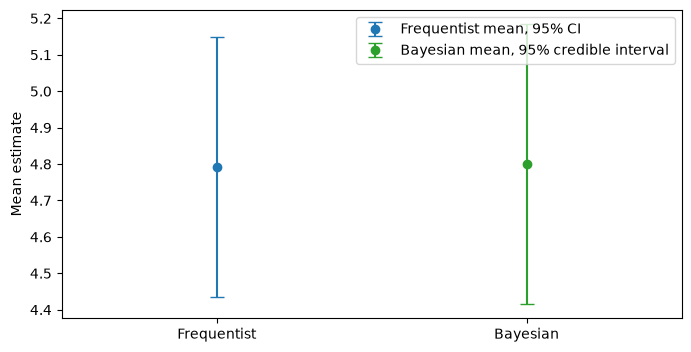

In [4]:
fig, ax = plt.subplots(figsize=(8, 4))
for x, m, ci, c, lab in [(1, freq_mean, freq_ci, "tab:blue", "Frequentist mean, 95% CI"),
                         (2, bayes_mean, bayes_ci, "tab:green", "Bayesian mean, 95% credible interval")]:
    ax.errorbar(x, m, yerr=[[m - ci[0]], [ci[1] - m]], fmt="o", color=c, capsize=5, label=lab)
ax.set_xticks([1, 2])
ax.set_xticklabels(["Frequentist", "Bayesian"])
ax.set_xlim(0.5, 2.5)
ax.set_ylabel("Mean estimate")
ax.legend()
plt.show()

## Coin example: Beta-Binomial updating

With a $\mathrm{Beta}(a,b)$ prior and $x$ heads in $n$ flips, the posterior is $\mathrm{Beta}(a+x,b+n-x)$. Three heads in three flips with a uniform prior gives $\mathrm{Beta}(4,1)$, posterior mean $0.8$. A strong $\mathrm{Beta}(20,20)$ prior barely moves from $0.5$ on the same data, showing the prior's role when data are scarce. The frequentist Wald interval at $\hat p=1$ degenerates to a single point, a known failure with tiny samples.

Beta(1,1)      posterior Beta(4,1) mean=0.800 95% CrI=(0.398, 0.994)
Beta(0.5,0.5)  posterior Beta(3.5,0.5) mean=0.875 95% CrI=(0.464, 1.000)
Beta(20,20)    posterior Beta(23,20) mean=0.535 95% CrI=(0.387, 0.680)


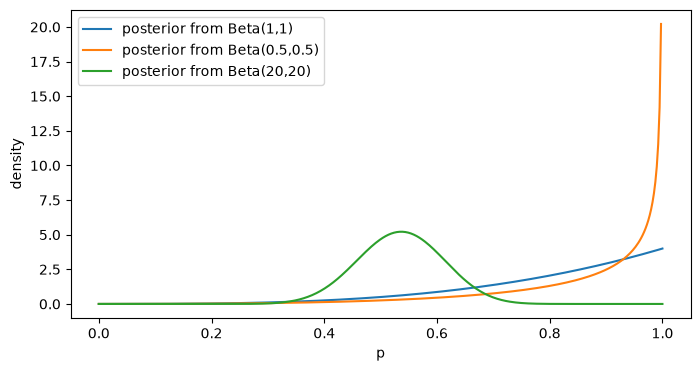

Wald SE at p_hat=1: 0.0


In [5]:
x, n = 3, 3
priors = {"Beta(1,1)": (1, 1), "Beta(0.5,0.5)": (0.5, 0.5), "Beta(20,20)": (20, 20)}
grid = np.linspace(0, 1, 400)
fig, ax = plt.subplots(figsize=(8, 4))
for name, (a, b) in priors.items():
    post = stats.beta(a + x, b + n - x)
    lo, hi = post.interval(0.95)
    print(f"{name:14s} posterior Beta({a + x},{b + n - x}) mean={post.mean():.3f} 95% CrI=({lo:.3f}, {hi:.3f})")
    ax.plot(grid, post.pdf(grid), label=f"posterior from {name}")
ax.set_xlabel("p")
ax.set_ylabel("density")
ax.legend()
plt.show()
p_hat = x / n
print("Wald SE at p_hat=1:", np.sqrt(p_hat * (1 - p_hat) / n))

## Prior influence shrinks with more data

Holding the true $p=0.7$ fixed, we increase $n$ and track the posterior mean under the uniform and the strong $\mathrm{Beta}(20,20)$ priors against the maximum-likelihood estimate $x/n$. The Bayesian estimates converge to the MLE as $n$ grows.

In [6]:
rng = np.random.default_rng(0)
flips = rng.random(2000) < 0.7
ns = [3, 10, 30, 100, 300, 1000, 2000]
for n_ in ns:
    xs = flips[:n_].sum()
    print(f"n={n_:5d}  MLE={xs / n_:.3f}  uniform={(1 + xs) / (2 + n_):.3f}  Beta(20,20)={(20 + xs) / (40 + n_):.3f}")

n=    3  MLE=1.000  uniform=0.800  Beta(20,20)=0.535
n=   10  MLE=0.600  uniform=0.583  Beta(20,20)=0.520
n=   30  MLE=0.667  uniform=0.656  Beta(20,20)=0.571
n=  100  MLE=0.630  uniform=0.627  Beta(20,20)=0.593
n=  300  MLE=0.627  uniform=0.626  Beta(20,20)=0.612
n= 1000  MLE=0.678  uniform=0.678  Beta(20,20)=0.671
n= 2000  MLE=0.697  uniform=0.697  Beta(20,20)=0.693
